# SmartServe — Data Quality Analysis

## Objective
Evaluate the quality, reliability, and consistency of SmartServe datasets.

## Analysis Areas
1. Missing Value Analysis
2. Duplicate Record Analysis
3. Data Type Validation
4. Invalid Value Detection
5. Referential Integrity
6. Business Rule Validation
7. Data Quality Summary

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_loader import load_all_data

data = load_all_data()

sns.set_theme(style="whitegrid")

print("SmartServe Data Quality Analysis")
print("=" * 50)
print(f"Datasets loaded: {len(data)}")

2026-11-07 12:39:00,582 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_date.csv
2026-11-07 12:39:00,587 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_store.csv
2026-11-07 12:39:00,591 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_product.csv
2026-11-07 12:39:00,599 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_customer.csv
2026-11-07 12:39:00,608 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_promotion.csv
2026-11-07 12:39:00,618 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartServe-Food-Intelligence\data\raw\dim_holiday.csv
2026-11-07 12:39:00,621 | INFO | src.data_loader | Loading data file: D:\Data Analysis Projects\SmartS

SmartServe Data Quality Analysis
Datasets loaded: 11


In [2]:

# Calculate missing values for every dataset

missing_summary = []

for dataset_name, df in data.items():

    for column in df.columns:

        missing_count = df[column].isna().sum()

        missing_percentage = (
            missing_count / len(df) * 100
            if len(df) > 0 else 0
        )

        missing_summary.append({
            "dataset": dataset_name,
            "column": column,
            "missing_count": missing_count,
            "missing_percentage": round(missing_percentage, 2)
        })

missing_df = pd.DataFrame(missing_summary)

# Display only columns containing missing values
missing_results = missing_df[
    missing_df["missing_count"] > 0
].sort_values(
    by="missing_percentage",
    ascending=False
)

print("MISSING VALUE ANALYSIS")
print("=" * 70)

if missing_results.empty:
    print("No missing values found.")
else:
    display(missing_results)


MISSING VALUE ANALYSIS


,dataset,column,missing_count,missing_percentage
12,dim_date,holiday_name,86,95.56


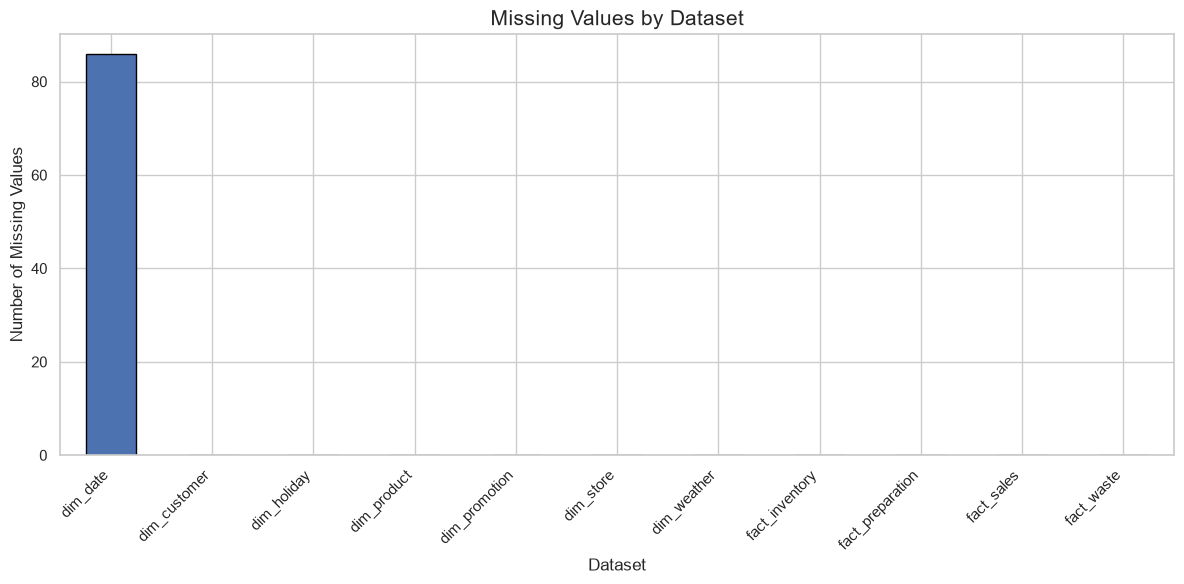

In [3]:

# Calculate total missing values per dataset

missing_by_dataset = (
    missing_df.groupby("dataset")["missing_count"]
    .sum()
    .sort_values(ascending=False)
)

# Plot missing values
plt.figure(figsize=(12, 6))

missing_by_dataset.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Missing Values by Dataset", fontsize=15)
plt.xlabel("Dataset")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()


In [4]:

# Define primary keys for all datasets

primary_keys = {
    "dim_date": "date_id",
    "dim_store": "store_id",
    "dim_product": "product_id",
    "dim_customer": "customer_id",
    "dim_promotion": "promotion_id",
    "dim_holiday": "holiday_id",
    "dim_weather": "weather_id",
    "fact_sales": "sales_id",
    "fact_preparation": "preparation_id",
    "fact_inventory": "inventory_id",
    "fact_waste": "waste_id"
}

duplicate_summary = []

for dataset_name, df in data.items():

    duplicate_rows = df.duplicated().sum()

    primary_key = primary_keys[dataset_name]

    duplicate_keys = df[primary_key].duplicated().sum()

    duplicate_summary.append({
        "dataset": dataset_name,
        "duplicate_rows": duplicate_rows,
        "duplicate_primary_keys": duplicate_keys
    })

duplicate_df = pd.DataFrame(duplicate_summary)

print("DUPLICATE RECORD ANALYSIS")
print("=" * 75)

display(duplicate_df)


DUPLICATE RECORD ANALYSIS


,dataset,duplicate_rows,duplicate_primary_keys
0,dim_date,0,0
1,dim_store,0,0
2,dim_product,0,0
3,dim_customer,0,0
4,dim_promotion,0,0
5,dim_holiday,0,0
6,dim_weather,0,0
7,fact_sales,0,0
8,fact_preparation,0,0
9,fact_inventory,0,0


In [5]:

# Generate a data type summary for every dataset

dtype_summary = []

for dataset_name, df in data.items():

    for column in df.columns:

        dtype_summary.append({
            "dataset": dataset_name,
            "column": column,
            "data_type": str(df[column].dtype),
            "unique_values": df[column].nunique(),
            "missing_values": df[column].isna().sum()
        })

dtype_df = pd.DataFrame(dtype_summary)

print("DATA TYPE ANALYSIS")
print("=" * 80)

display(dtype_df)


DATA TYPE ANALYSIS


,dataset,column,data_type,unique_values,missing_values
0,dim_date,date_id,int64,90,0
1,dim_date,full_date,str,90,0
2,dim_date,year,int64,1,0
3,dim_date,quarter,int64,1,0
4,dim_date,month,int64,3,0
...,...,...,...,...,...
95,fact_waste,product_id,str,20,0
96,fact_waste,waste_reason_id,str,5,0
97,fact_waste,quantity_wasted,int64,18,0
98,fact_waste,unit_cost,float64,13,0


In [6]:

# Define invalid-value checks

invalid_checks = {
    "fact_sales": {
        "Non-positive sales quantity": lambda df: df["quantity"] <= 0,
        "Negative selling price": lambda df: df["unit_price"] < 0,
        "Negative discount": lambda df: df["discount_amount"] < 0,
        "Negative net sales": lambda df: df["net_sales"] < 0,
        "Negative cost amount": lambda df: df["cost_amount"] < 0,
    },

    "dim_product": {
        "Non-positive shelf life": lambda df: df["shelf_life_hours"] <= 0,
        "Non-positive preparation time": lambda df: df["preparation_time"] <= 0,
        "Negative product cost": lambda df: df["unit_cost"] < 0,
    },

    "fact_preparation": {
        "Negative planned quantity": lambda df: df["planned_qty"] < 0,
        "Negative actual quantity": lambda df: df["actual_qty"] < 0,
    },

    "fact_inventory": {
        "Negative inventory": lambda df: (
            (df["opening_stock"] < 0) |
            (df["received_qty"] < 0) |
            (df["prepared_qty"] < 0) |
            (df["sold_qty"] < 0) |
            (df["closing_stock"] < 0) |
            (df["damaged_qty"] < 0) |
            (df["expired_qty"] < 0)
        ),
    },

    "fact_waste": {
        "Non-positive waste quantity": lambda df: df["quantity_wasted"] <= 0,
        "Negative waste cost": lambda df: df["waste_cost"] < 0,
    }
}

invalid_results = []

for dataset_name, checks in invalid_checks.items():

    df = data[dataset_name]

    for check_name, condition in checks.items():

        issue_count = int(condition(df).sum())

        invalid_results.append({
            "dataset": dataset_name,
            "check": check_name,
            "invalid_records": issue_count,
            "status": "PASS" if issue_count == 0 else "FAIL"
        })

invalid_df = pd.DataFrame(invalid_results)

print("INVALID VALUE ANALYSIS")
print("=" * 85)

display(invalid_df)


INVALID VALUE ANALYSIS


,dataset,check,invalid_records,status
0,fact_sales,Non-positive sales quantity,0,PASS
1,fact_sales,Negative selling price,0,PASS
2,fact_sales,Negative discount,0,PASS
3,fact_sales,Negative net sales,0,PASS
4,fact_sales,Negative cost amount,0,PASS
5,dim_product,Non-positive shelf life,0,PASS
6,dim_product,Non-positive preparation time,0,PASS
7,dim_product,Negative product cost,0,PASS
8,fact_preparation,Negative planned quantity,0,PASS
9,fact_preparation,Negative actual quantity,0,PASS


In [7]:

# Define foreign key relationships

relationships = [
    ("fact_sales", "date_id", "dim_date", "date_id"),
    ("fact_sales", "store_id", "dim_store", "store_id"),
    ("fact_sales", "product_id", "dim_product", "product_id"),
    ("fact_sales", "customer_id", "dim_customer", "customer_id"),
    ("fact_sales", "promotion_id", "dim_promotion", "promotion_id"),

    ("fact_preparation", "date_id", "dim_date", "date_id"),
    ("fact_preparation", "store_id", "dim_store", "store_id"),
    ("fact_preparation", "product_id", "dim_product", "product_id"),

    ("fact_inventory", "date_id", "dim_date", "date_id"),
    ("fact_inventory", "store_id", "dim_store", "store_id"),
    ("fact_inventory", "product_id", "dim_product", "product_id"),

    ("fact_waste", "date_id", "dim_date", "date_id"),
    ("fact_waste", "store_id", "dim_store", "store_id"),
    ("fact_waste", "product_id", "dim_product", "product_id"),
]

referential_results = []

for child_table, child_column, parent_table, parent_column in relationships:

    child_df = data[child_table]
    parent_df = data[parent_table]

    valid_keys = set(parent_df[parent_column].dropna())

    # Allow NULL promotion IDs because a sale may have no promotion.
    child_keys = child_df[child_column]

    invalid_count = int(
        (~child_keys.isna() & ~child_keys.isin(valid_keys)).sum()
    )

    referential_results.append({
        "relationship": (
            f"{child_table}.{child_column} -> "
            f"{parent_table}.{parent_column}"
        ),
        "invalid_references": invalid_count,
        "status": "PASS" if invalid_count == 0 else "FAIL"
    })

referential_df = pd.DataFrame(referential_results)

print("REFERENTIAL INTEGRITY ANALYSIS")
print("=" * 100)

display(referential_df)


REFERENTIAL INTEGRITY ANALYSIS


,relationship,invalid_references,status
0,fact_sales.date_id -> dim_date.date_id,0,PASS
1,fact_sales.store_id -> dim_store.store_id,0,PASS
2,fact_sales.product_id -> dim_product.product_id,0,PASS
3,fact_sales.customer_id -> dim_customer.custome...,0,PASS
4,fact_sales.promotion_id -> dim_promotion.promo...,0,PASS
5,fact_preparation.date_id -> dim_date.date_id,0,PASS
6,fact_preparation.store_id -> dim_store.store_id,0,PASS
7,fact_preparation.product_id -> dim_product.pro...,0,PASS
8,fact_inventory.date_id -> dim_date.date_id,0,PASS
9,fact_inventory.store_id -> dim_store.store_id,0,PASS


In [8]:

# Calculate overall data quality metrics

total_datasets = len(data)

total_records = sum(len(df) for df in data.values())

total_missing = sum(
    df.isna().sum().sum()
    for df in data.values()
)

total_duplicates = sum(
    df.duplicated().sum()
    for df in data.values()
)

total_invalid = invalid_df["invalid_records"].sum()

total_invalid_references = (
    referential_df["invalid_references"].sum()
)

# Create summary table
quality_summary = pd.DataFrame({
    "Quality Metric": [
        "Total Datasets",
        "Total Records",
        "Missing Values",
        "Duplicate Rows",
        "Invalid Records",
        "Invalid Foreign Key References"
    ],

    "Result": [
        total_datasets,
        total_records,
        total_missing,
        total_duplicates,
        total_invalid,
        total_invalid_references
    ]
})

print("SMARTSERVE — FINAL DATA QUALITY SUMMARY")
print("=" * 65)

display(quality_summary)

# Overall status
if (
    total_duplicates == 0
    and total_invalid == 0
    and total_invalid_references == 0
):
    print("\nDATA QUALITY STATUS: PASSED")
else:
    print("\nDATA QUALITY STATUS: REVIEW REQUIRED")


SMARTSERVE — FINAL DATA QUALITY SUMMARY


,Quality Metric,Result
0,Total Datasets,11
1,Total Records,145547
2,Missing Values,86
3,Duplicate Rows,0
4,Invalid Records,0
5,Invalid Foreign Key References,0



DATA QUALITY STATUS: PASSED


## Final Data Quality Findings

The SmartServe prototype contains 11 datasets covering sales,
customers, stores, products, promotions, weather, inventory,
preparation, and waste.

The data quality investigation examined:

- Missing values
- Duplicate records
- Data types
- Invalid business values
- Referential integrity

The missing holiday names in dim_date are expected because
only four dates in the prototype period are holidays.

The generated datasets showed no duplicate records, invalid
business values, or invalid foreign key references in the
checks performed.

Overall, the datasets are suitable for the next stage of
exploratory analysis, subject to further business-logic review.